# M-TCIR: trait-based and random responding in TIRT dyads

Model two-statement choices as a mixture of trait-based, biased random and
uniform random responding. This dyad adaptation follows the three response
mechanisms in [Peng et al. (2024)](https://doi.org/10.1177/10944281231181642).

## Combine three response states

Let $p$ index people and $b$ index two-statement blocks. The response
$Y_{pb}=1$ favors the first statement $j$ over the second $k$. In the
trait-based state, its probability is the TIRT probit probability

$$
q_{pb}=\Phi\!\left(
\lambda_j\theta_{p,t(j)}-\lambda_k\theta_{p,t(k)}-\gamma_b
\right).
$$

$\lambda_j$ is the signed loading on the trait score
$\theta_{p,t(j)}$, $\gamma_b$ is the pair threshold and $\Phi$ is the
standard normal cumulative distribution function. The two fixed residual
variances of 0.5 give a comparison residual SD of one.

For each response, $\pi_b$ is the probability of using a random state.
Within random responding, the uniform state's share is
$h_{pb}=\operatorname{logistic}(\eta_p-\beta_b)$. The person parameter
$\eta_p$ increases this share and the block parameter $\beta_b$ decreases
it. Their difference is converted by $\operatorname{logistic}(x)=1/(1+e^{-x})$.

- **Trait-based** has weight $1-\pi_b$ and chooses the first statement with probability $q_{pb}$.
- **Biased random** has weight $\pi_b(1-h_{pb})$ and chooses it with probability $c_b$.
- **Uniform random** has weight $\pi_b h_{pb}$ and chooses it with probability $1/2$.

Summing the three contributions gives the probability used in the fit:

$$
P(Y_{pb}=1)=(1-\pi_b)q_{pb}+\pi_b(1-h_{pb})c_b+\tfrac12\pi_b h_{pb}.
$$

## Read the design and choices

The bundled simulation includes 100 respondents and nine dyads. It uses a
trait-based generator. Here it provides binary choices for illustrating
the three-state model.

In [1]:
import seaborn as sns

import pyfcirt as fc

sns.set_theme(style="ticks")

example = fc.load_example("jrt_tirt", model="TIRT", n_persons=100)
design = example.data.design
design.head(3)

,block_id,position,statement_id,trait,keying
0,B1,1,S1,theta1,1
1,B1,2,S2,theta2,1
2,B2,1,S3,theta2,1


A response of 1 favors the first statement. A response of 0 favors the
second. The first three rows show respondent J001 in blocks B1, B2 and B3.

In [2]:
responses = example.data.responses.frame
responses.head(3)

,person_id,block_id,statement_1,statement_2,response
0,J001,B1,S1,S2,0
1,J001,B2,S3,S4,0
2,J001,B3,S5,S6,0


## Build the PyMC model

The indexing cell shows how response labels align with the person,
trait and statement axes.

In [3]:
import arviz as az
import arviz_plots as azp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
from pymc.model.fgraph import clone_model

from pyfcirt.models.dist import TIRTDistribution

people = pd.Index(responses.person_id.unique(), name="person")
blocks = pd.Index(design.block_id.unique(), name="block")
statements = design.drop_duplicates("statement_id").set_index("statement_id")
traits = pd.Index(statements.trait.unique(), name="trait")
person = people.get_indexer(responses.person_id)
block = blocks.get_indexer(responses.block_id)
pair = np.column_stack(
    [
        statements.index.get_indexer(responses.statement_1),
        statements.index.get_indexer(responses.statement_2),
    ]
)
trait = traits.get_indexer(statements.trait)[pair]
keying = statements.keying.to_numpy(dtype=float)
y = responses.response.to_numpy(dtype=int)
corr_row, corr_col = np.triu_indices(len(traits), k=1)
coords = {
    "person": people,
    "trait": traits,
    "statement": statements.index,
    "block": blocks,
    "obs": responses.index,
    "trait_pair": [f"{traits[a]} / {traits[b]}" for a, b in zip(corr_row, corr_col, strict=True)],
}

## Define trait-based and mixture choices

Both fits use the same priors for traits, loadings and comparison
thresholds. Define those variables once, then give each model its own
likelihood for the observed choices.

In [4]:
effects = np.zeros((len(responses), 2))
variances = np.full((len(responses), 2), 0.5)

with pm.Model(coords=coords) as tirt:
    # The LKJ prior fixes each trait's population SD at one.
    chol = pm.LKJCorr("trait_cholesky", n=len(traits), eta=1)
    pm.Deterministic(
        "trait_correlation",
        (chol @ chol.T)[corr_row, corr_col],
        dims="trait_pair",
    )
    theta = pm.MvNormal(
        "theta",
        mu=np.zeros(len(traits)),
        chol=chol,
        shape=(len(people), len(traits)),
        dims=("person", "trait"),
    )
    # Keying supplies the sign of each statement loading.
    loading_magnitude = pm.LogNormal("loading_magnitude", 0, 0.5, dims="statement")
    gamma = pm.Normal("gamma", 0, 2, dims="block")

# Give the baseline and mixture separate observed likelihoods.
model = clone_model(tirt)
with tirt:
    TIRTDistribution(
        "response",
        theta[person[:, None], trait],
        (keying * loading_magnitude)[pair],
        gamma[block, None],
        statement_effect=effects,
        residual_variance=variances,
        observed=y,
        dims="obs",
    )

In [5]:
with model:
    # Trait-based choice probability.
    normal_response = TIRTDistribution.dist(
        model["theta"][person[:, None], trait],
        (keying * model["loading_magnitude"])[pair],
        model["gamma"][block, None],
        statement_effect=effects,
        residual_variance=variances,
    )
    normal_logit = pm.logp(normal_response, 1) - pm.logp(normal_response, 0)
    # Priors for the random-response states and their weights.
    pi = pm.Beta("pi", 1, 1, dims="block")
    c = pm.Beta("c", 1, 1, dims="block")
    eta = pm.Normal("eta", 0, 1, dims="person")
    beta = pm.Normal("beta", 0, 1, dims="block")
    h = pm.math.sigmoid(eta[person] - beta[block])
    # p(y) = (1 - pi) p_normal(y) + pi (1 - h) p_biased(y) + pi h p_coin(y).
    weights = pt.stack([1 - pi[block], pi[block] * (1 - h), pi[block] * h], axis=-1)
    component_logits = pt.stack(
        [
            normal_logit,
            pt.log(c[block]) - pt.log1p(-c[block]),
            pt.zeros_like(h),
        ],
        axis=-1,
    )
    components = pm.Bernoulli.dist(logit_p=component_logits)
    # Sum over the three states for each possible observed answer.
    answers = pt.arange(2)[:, None, None]
    log_joint = pt.log(weights) + pm.logp(components, answers)
    log_choice = pm.math.logsumexp(log_joint, axis=-1)
    pm.Bernoulli(
        "response",
        logit_p=log_choice[1] - log_choice[0],
        observed=y,
        dims="obs",
    )

## Fit and diagnose

The results shown use four chains, with 3,500 warmup iterations
and 3,000 retained draws per chain. The parallel-chain setting uses
multiple devices. [Estimation backend setup](../examples/estimation_backends.md)

In [6]:
with model:
    idata = pm.sample(draws=3000, tune=3500, chains=4, random_seed=2026111709)

The maximum R-hat is 1.003. The minimum bulk and tail effective sample
sizes are 2,155 and 3,274, and there are zero divergences.

In [7]:
import numpy as np

posterior = idata.posterior.to_dataset()[
    ["theta", "loading_magnitude", "gamma", "pi", "c", "eta", "beta"]
].reset_coords(drop=True)
with np.errstate(invalid="ignore", divide="ignore"):
    r_hat = az.rhat(posterior).max().to_array().max().item()
    bulk = az.ess(posterior, method="bulk").min().to_array().min().item()
    tail = az.ess(posterior, method="tail").min().to_array().min().item()

print(f"Max R-hat: {r_hat:.3f}")
print(f"Min bulk / tail ESS: {bulk:.0f} / {tail:.0f}")
print("Divergences:", int(idata.sample_stats.diverging.sum()))

Max R-hat: 1.002
Min bulk / tail ESS: 3655 / 5204
Divergences: 0


The density and rank panels show the B1 mixture and gate parameters.
Their rank-test p-values are 0.78, 0.33 and 0.03.

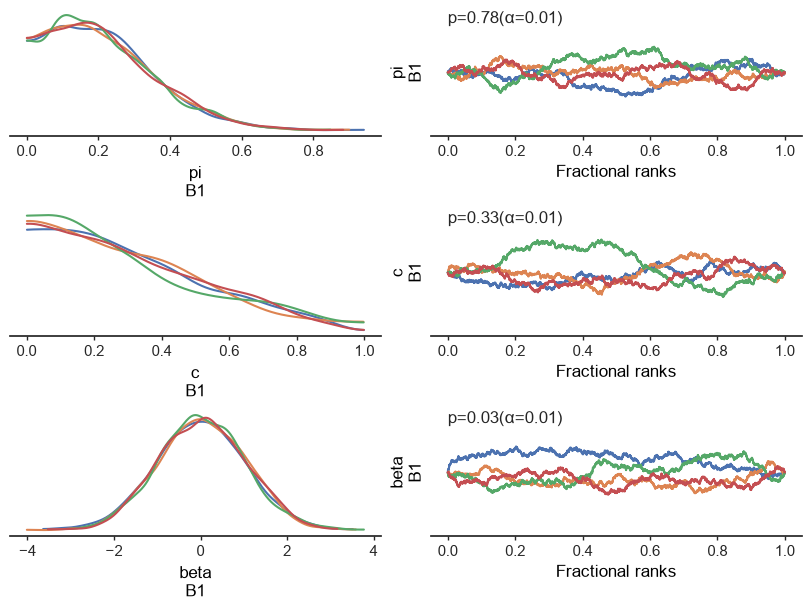

In [8]:
rank_posterior = idata.posterior.to_dataset()[["pi", "c", "beta"]].sel(block=blocks[:1])
azp.plot_rank_dist(
    rank_posterior,
    compact=False,
    backend="matplotlib",
    figure_kwargs={"figsize": (8, 6), "layout": "constrained"},
)
plt.show()

## Compare predictive fit with TIRT

Fit TIRT to the same binary choices in the same row order. Compute
the pointwise log likelihood of each observed comparison and pass it to
[ArviZ's `compare()`](https://python.arviz.org/en/stable/api/generated/arviz.compare.html).
Here leave-one-out prediction holds out one comparison. Other answers
from that respondent remain available to estimate their trait scores.

In [9]:
with tirt:
    tirt_fit = pm.sample(draws=1200, tune=1800, chains=4)

In [10]:
for fit, graph in [(idata, model), (tirt_fit, tirt)]:
    # Evaluate log p(observed choice) at each posterior draw.
    with clone_model(graph) as evaluation:
        pm.Deterministic("choice_logp", pm.logp(evaluation["response"], y), dims="obs")
    logp = pm.compute_deterministics(
        fit.posterior.to_dataset(),
        model=evaluation,
        var_names=["choice_logp"],
    )
    fit["log_likelihood"] = logp.rename({"choice_logp": "response"})

comparison = az.compare({"M-TCIR": idata, "TIRT": tirt_fit}, var_name="response", round_to=2)
comparison

D:\CodexEnvs\pyfcirt\Lib\site-packages\rich\live.py:260: UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

D:\CodexEnvs\pyfcirt\Lib\site-packages\rich\live.py:260: UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

,rank,elpd_diff,dse,p_worse,diag_diff,diag_elpd,p,elpd,se,weight
TIRT,0,0.00,0.00,NaN,,91 k̂ > 0.70,196.34,-493.49,14.17,1.0
M-TCIR,1,-22.92,3.45,1.0,,1 k̂ > 0.70,183.77,-516.41,11.57,0.0


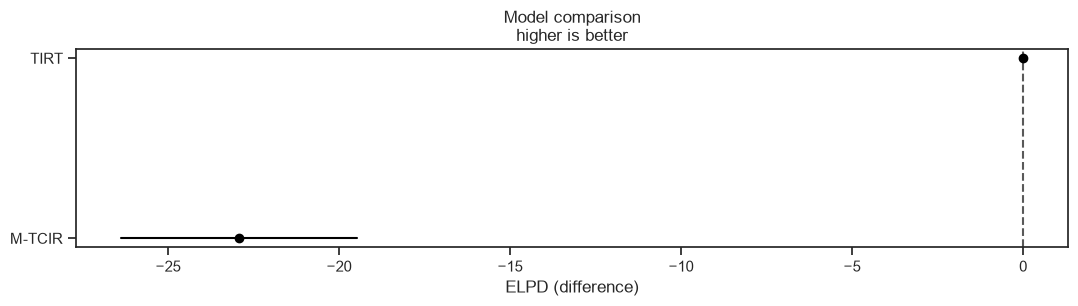

In [11]:
azp.plot_compare(comparison, backend="matplotlib")
plt.show()

The PSIS-LOO estimate favors TIRT by 22.92 ELPD units (paired standard error 3.45). The Pareto diagnostics flag 91 of the 900 comparisons for TIRT and one for M-TCIR above 0.70. These diagnostics limit confidence in the estimated difference.